In [1]:
from helpers import *
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib as mpl
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.size'] = 14
plt.rcParams['mathtext.fontset'] = 'stix'  # Use STIX fonts for math symbols

color_surface = 'PuOr_r'
color_S = 'r'
color_stream = 'gray'
color_u = 'k'

In [2]:
data_index = {
    'a': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.4_WF/solution.nc', r'($a$)', 0.4, 0.2),
    'b': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.4_IWF/solution.nc', r'($b$)', 0.4, 0.6),
    'c': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/solution.nc', r'($c$)', 0.6, 0.1),
    'd': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.8_PO3/solution.nc', r'($d$)', 0.8, 0.2),
    'e': ('Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.8_RPO2/solution.nc', r'($e$)', 0.8, 0.6),
}

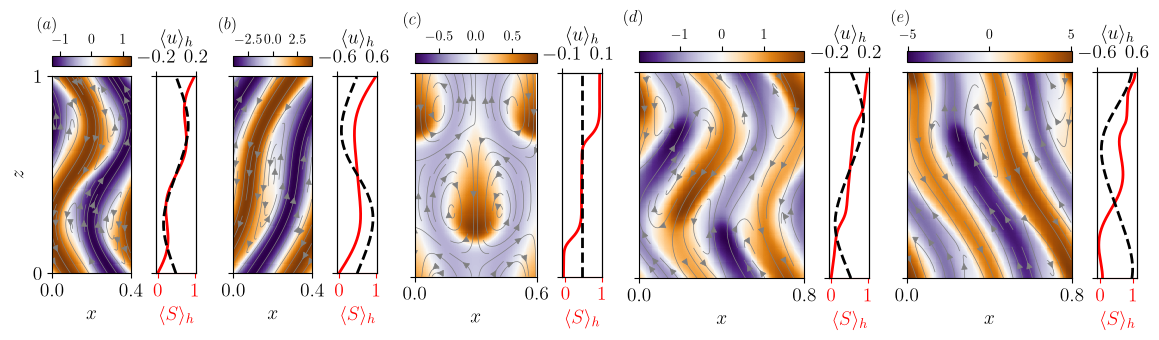

In [3]:
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Adjust figure size for a single-column or wide-column PRL layout
fig = plt.figure(figsize=(14, 3.5)) 
# width_ratios should ideally match your Lx values for consistency
gs = gridspec.GridSpec(1, 5, width_ratios=[0.5, 0.5, 0.65, 0.8, 0.8], wspace=0.2)
axes = [fig.add_subplot(gs[0, i]) for i in range(5)]


for i, ax in enumerate(axes):
    label_name, (path, label, Lx, u_max) = list(data_index.items())[i]
    # Load data (using your existing functions)
    # [x, z] = return_coordinates(path)
    [x, z, t, s, u, w] = return_fields(path)
    smin = np.min(s)
    smax = np.max(s)
    max_abs = max(abs(smin), abs(smax))

    # Plot Field
    X, Z = np.meshgrid(x, z)
    h = ax.pcolormesh(X, Z, s.T,vmin=-max_abs,vmax=max_abs, cmap=color_surface, shading='auto')
    ax.streamplot(X, Z, u.T, w.T, color=color_stream, density=0.6, linewidth=0.5, arrowsize=1)
    
    # Format Main Axis
    ax.set_xlabel('$x$')
    ax.set_ylim([0, 1])
    ax.set_xlim([0, Lx])
    ax.set_xticks([0, Lx])
    ax.set_aspect('equal', adjustable='box')
    
    if i == 0:
        ax.set_ylabel('$z$')
        ax.set_yticks([0, 1])
    else:
        ax.set_yticks([0, 1], []) # Hide labels for inner plots

    # --- DIVIDER LOGIC ---
    divider = make_axes_locatable(ax)

    # Colorbar at Top
    cax = divider.append_axes("top", size="5%", pad=0.1)
    cbar = fig.colorbar(h, cax=cax, orientation='horizontal')
    cbar.ax.tick_params(labelsize=10)
    cax.xaxis.set_ticks_position('top') 
    
    # 1. Profile S
    ax_s = divider.append_axes("right", size=0.4, pad=0.25) 
    ax_s.plot(s.mean(axis=0) + z, z, color=color_S, lw=2)
    ax_s.set_xlabel(r'$\langle S \rangle_h$', color=color_S)
    ax_s.tick_params(axis='x', colors=color_S)
    ax_s.spines['bottom'].set_color(color_S)
    ax_s.set_xticks([0, 1])
    ax_s.set_yticks([0, 1], [])
    ax_s.set_ylim([0, 1])
    

    # 2. Profile of u
    ax_u = ax_s.twiny()  # Create a twin axis for u
    ax_u.plot(u.mean(axis=0), z, linestyle='--', color=color_u, lw=2)
    ax_u.set_xlabel(r'$\langle u \rangle_h$', color=color_u)
    ax_u.tick_params(axis='x', colors=color_u)
    ax_u.spines['top'].set_color(color_u)
    ax_u.set_xlim(-u_max, u_max)
    ax_u.set_xticks([-u_max, u_max])

    if i == 0 or i == 1:
        ax.text(-0.2, 1.3, label, transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top')
    else:
        ax.text(-0.1, 1.3, label, transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top')

    

# Save with bbox_inches='tight' to handle the appended axes correctly
plt.savefig('Fig1.png', format='png', dpi=600, bbox_inches='tight')
plt.savefig('Fig1.pdf', format='pdf', dpi=600, bbox_inches='tight')
# plt.savefig('Fig1.eps', format='eps', dpi=600, bbox_inches='tight')
plt.show()